# Natural Language Processing 3 - Transformers

## Summary

Lessons 1 and 2 gave us three sentiment models: rules (TextBlob), logistic regression on TF-IDF, and our own neural network with word embeddings. They reach up to **85%** on the test reviews, but all of them fail most of our tricky sentences, because they all see a **bag of words**: no order, no context.

Today: **transformers**, the models behind BERT and ChatGPT. They read every word **in the context of the other words**, and they come **pretrained** on huge amounts of text.

The notebook has three parts:

| Part | What we do |
|---|---|
| **Part 1** | We follow the slides, one idea at a time, with questions and answers |
| **Part 2** | The whole project once more, in **one cell**: the complete workflow from data to scoreboard |
| **Part 3** | *(Optional)* Project examples: Marvin the chatbot and a text generator, with embeddings and transformers |

**Part 1**:

| Section | What we do | Slides |
|---|---|---|
| 0–1 | Setup, the reviews, the three models from lessons 1 and 2 | 3 |
| 2 | Why context matters | 4 |
| 3 | What is a transformer? | 5 |
| 4 | Attention by hand: query, key, value | 6–9 |
| 5 | Word order and positions | 10 |
| 6 | How far can attention look? Three ways of attention | 11–12 |
| 7 | The blocks, stacked | 13–14 |
| 8 | Subword tokens | 15 |
| 9 | One sentence, start to finish | 16 |
| 10 | Pretraining: guess the missing word | 17 |
| 11 | Pretrained, then fine-tuned: the transformer on our reviews | 18–19 |
| 12 | The showdown | 20–22 |
| 13 | Limits | 23 |
| 14 | Four ways to use a pretrained model, and RAG | 24–27 |
| 15 | Recap | 28 |

**Note:** the cells marked with 🤗 need Hugging Face models. Run the 🤗 cell in section 0 once at home with internet: it saves all models into a `models` folder (about 900 MB), and from then on the notebook runs offline.

## 0. Setup

We load our libraries. Our data (**movie_reviews.csv**), the GloVe word vectors (**glove-wiki-gigaword-50.gz**, about 70 MB) and the NLTK tools (in the **nltk_data** folder) must be in the same folder as this notebook.

In [1]:
import os, re, time, gzip, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from textblob import TextBlob   
import torch
import torch.nn as nn

pd.set_option("display.max_colwidth", 120)
DATA_DIR = "." 

# Hugging Face models: use the local "models" folder if it is there, otherwise download by name
MODELS_DIR = os.path.join(DATA_DIR, "models")
def local_or_hub(name):
    path = os.path.join(MODELS_DIR, name.split("/")[-1])
    return path if os.path.isdir(path) else name

**🤗 Run once with internet (optional):** saves the three Hugging Face models into a `models` folder next to this notebook (about 900 MB). After that every 🤗 cell loads from that folder, and the notebook runs **offline**. You can also copy the `models` folder to other laptops.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModelForMaskedLM, AutoModelForCausalLM

MODELS = {"distilbert/distilbert-base-uncased-finetuned-sst-2-english": AutoModelForSequenceClassification,   
          "distilbert/distilbert-base-uncased": AutoModelForMaskedLM,                                  
          "distilbert/distilgpt2": AutoModelForCausalLM}                                           
for name, model_class in MODELS.items():
    path = os.path.join(MODELS_DIR, name.split("/")[-1])
    if os.path.isdir(path):
        print("already there:", path)
        continue
    AutoTokenizer.from_pretrained(name).save_pretrained(path)      
    model_class.from_pretrained(name).save_pretrained(path)     
    print("saved:", path)

W1029 13:16:25.388000 95366 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved: ./models/distilbert-base-uncased-finetuned-sst-2-english


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved: ./models/distilbert-base-uncased


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved: ./models/distilgpt2


## 1. The reviews and our three models

Same reviews and same split as lessons 1 and 2 (`random_state=42`), so the **400 test reviews are exactly the same**. As in lesson 2, 320 training reviews are kept apart as a **validation set**.

In [3]:
df = pd.read_csv(os.path.join(DATA_DIR, "movie_reviews.csv"))  
df["y"] = (df["label"] == "pos").astype(int)    

from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)  
train_df, val_df = train_test_split(train_df, test_size=0.2, stratify=train_df["y"], random_state=42)
y_test = test_df["y"].values
print("Training:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))

Training: 1280 | Validation: 320 | Test: 400


Our **8 tricky sentences** from lessons 1 and 2: short, made up, and hard on purpose (negation, contrast with *but*, sarcasm).

In [4]:
tricky = pd.DataFrame({
    "sentence": [
        "This movie was great!",
        "This movie was not good.",
        "Not bad at all, I really enjoyed it.",
        "I didn't hate it.",
        "I loved the trailer, but the film was a disaster.",
        "Oh great, another two hours of my life I will never get back.",
        "The acting was terrible but the story was wonderful.",
        "Absolutely brilliant, a must-see!",
    ],
    "truth": ["pos", "neg", "pos", "pos", "neg", "neg", "pos", "pos"],
})
tricky

,sentence,truth
0,This movie was great!,pos
1,This movie was not good.,neg
2,"Not bad at all, I really enjoyed it.",pos
3,I didn't hate it.,pos
4,"I loved the trailer, but the film was a disaster.",neg
5,"Oh great, another two hours of my life I will never get back.",neg
6,The acting was terrible but the story was wonderful.,pos
7,"Absolutely brilliant, a must-see!",pos


We rebuild the three models from lessons 1 and 2 with exactly the same settings (about 30 seconds). You don't need to read this cell in detail: it is lessons 1 and 2 in short.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
results = {}

# 1. Rules: TextBlob (positive polarity -> pos)
results["1. Rules: TextBlob"] = ((test_df["text"].apply(lambda t: TextBlob(t).sentiment.polarity) > 0).astype(int) == y_test).mean()
tricky["TextBlob"] = np.where(tricky["sentence"].apply(lambda s: TextBlob(s).sentiment.polarity) > 0, "pos", "neg")

# 2. TF-IDF + logistic regression, trained on all 1,600 training reviews (lesson 1)
train_full = pd.concat([train_df, val_df])
tfidf_vec = TfidfVectorizer()
logreg = LogisticRegression(max_iter=1000).fit(tfidf_vec.fit_transform(train_full["text"]), train_full["y"])
results["2. TF-IDF + logistic regression"] = logreg.score(tfidf_vec.transform(test_df["text"]), y_test)
tricky["Log. reg."] = np.where(logreg.predict(tfidf_vec.transform(tricky["sentence"])) == 1, "pos", "neg")

# 3. Our EmbeddingBag network (lesson 2): 64 learned numbers per word, averaged, one neuron
def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

counts = Counter(w for text in train_df["text"] for w in tokenize(text))
itos = ["<unk>"] + [w for w, c in counts.items() if c >= 2]
stoi = {w: i for i, w in enumerate(itos)}

def make_batch(texts):
    ids = [torch.tensor([stoi.get(w, 0) for w in tokenize(t)]) for t in texts]
    offsets = torch.tensor([0] + [len(x) for x in ids[:-1]]).cumsum(0)
    return torch.cat(ids), offsets

def batches(data, batch_size=32, shuffle=False, rng=None):
    order = rng.permutation(len(data)) if shuffle else np.arange(len(data))
    for start in range(0, len(data), batch_size):
        part = data.iloc[order[start:start + batch_size]]
        ids, offsets = make_batch(part["text"].tolist())
        yield ids, offsets, torch.tensor(part["y"].values, dtype=torch.float32)

class SentimentNet(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, dropout=0.3):
        super().__init__()
        self.embedding = nn.EmbeddingBag(vocab_size, embed_dim, mode="mean")
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(embed_dim, 1)
    def forward(self, ids, offsets):
        return self.output(self.dropout(self.embedding(ids, offsets))).squeeze(1)

def accuracy(model, data):
    model.eval()
    with torch.no_grad():
        return sum(((model(i, o) > 0).float() == l).sum().item() for i, o, l in batches(data, 256)) / len(data)

torch.manual_seed(0); rng = np.random.default_rng(0)
net = SentimentNet(len(itos))
optimizer = torch.optim.Adam(net.parameters(), lr=0.005)
criterion = nn.BCEWithLogitsLoss()
best_val, best_state = 0, None
for epoch in range(1, 21):                              # 20 epochs, keep the best validation epoch
    net.train()
    for ids, offsets, labels in batches(train_df, 32, shuffle=True, rng=rng):
        loss = criterion(net(ids, offsets), labels)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    val_acc = accuracy(net, val_df)
    if val_acc > best_val:
        best_val, best_state = val_acc, {k: v.clone() for k, v in net.state_dict().items()}
net.load_state_dict(best_state)
results["3. Neural network (EmbeddingBag)"] = accuracy(net, test_df)

def predict_net(sentences):                             # probability of positive
    net.eval()
    with torch.no_grad():
        ids, offsets = make_batch(sentences)
        return torch.sigmoid(net(ids, offsets)).numpy()
tricky["Neural net"] = np.where(predict_net(tricky["sentence"].tolist()) > 0.5, "pos", "neg")

display(pd.Series(results, name="test accuracy").map("{:.1%}".format))
for m in ["TextBlob", "Log. reg.", "Neural net"]:
    print(f"{m:10} tricky sentences right: {(tricky[m] == tricky['truth']).sum()} of 8")
tricky

1. Rules: TextBlob                  59.5%
2. TF-IDF + logistic regression     80.2%
3. Neural network (EmbeddingBag)    85.0%
Name: test accuracy, dtype: str

TextBlob   tricky sentences right: 4 of 8
Log. reg.  tricky sentences right: 2 of 8
Neural net tricky sentences right: 3 of 8


,sentence,truth,TextBlob,Log. reg.,Neural net
0,This movie was great!,pos,pos,neg,pos
1,This movie was not good.,neg,neg,neg,neg
2,"Not bad at all, I really enjoyed it.",pos,pos,neg,neg
3,I didn't hate it.,pos,neg,neg,neg
4,"I loved the trailer, but the film was a disaster.",neg,pos,neg,pos
5,"Oh great, another two hours of my life I will never get back.",neg,pos,pos,pos
6,The acting was terrible but the story was wonderful.,pos,neg,neg,neg
7,"Absolutely brilliant, a must-see!",pos,pos,neg,pos


<span style="color:red;"><b>Question:</b> Look at the tricky sentences. Which ones does <b>no</b> method get right, and what do they have in common?</span>

<span style="color:green;"><b>Answer:</b></span><br>
*"I didn't hate it."*, the sarcastic *"Oh great, another two hours..."* and *"The acting was terrible but the story was wonderful."* are wrong for all three.

In all of them the meaning depends on **how the words relate to each other**: *didn't* flips *hate*, *but* decides which half counts, *great* is meant ironically. All three methods see each word **on its own** (rules, a bag of words, an average of word vectors), so they can't see these relations.

Careful with logistic regression: it says *neg* for 7 of the 8 sentences, even for *"This movie was great!"*. Its two right answers come from that habit, not from understanding.

## 2. Why context matters

Our network from lesson 2 averages the word vectors. So what happens if we change the **order** of the words?

In [6]:
for s in ["This movie was not good.", "This movie was good not.", "not This was good movie."]:
    print(f"{s:28} -> probability positive {predict_net([s])[0]:.3f}")

This movie was not good.     -> probability positive 0.457
This movie was good not.     -> probability positive 0.457
not This was good movie.     -> probability positive 0.457


<span style="color:red;"><b>Question:</b> All three sentences get <b>exactly</b> the same probability. Why? And what does that mean for <i>plot</i> in <i>"There is a plot to this movie"</i> and <i>"They have a plot to extort 500k"</i>?</span>

<span style="color:green;"><b>Answer:</b></span><br>
The network takes the **average** of the word vectors, and an average doesn't change when the order changes. It is still a **bag of words**, only with smarter word vectors.

For the same reason *plot* has **one** vector, whatever sentence it is in: the story of a film and a secret plan get the same numbers. A good model must give each word a vector **that depends on the sentence**. That is what a transformer does.

## 3. What is a transformer?

A **transformer** is a neural network for text that reads **all words at once** and lets every word **look at the other words** (attention), in several layers. Every word gets a vector that depends on the sentence.

The model we use today is **DistilBERT**. The `transformers` library can build its structure without downloading anything (with random weights, so it knows nothing yet). Let's look inside:

In [7]:
from transformers import DistilBertConfig, DistilBertForSequenceClassification

config = DistilBertConfig()                         
empty_model = DistilBertForSequenceClassification(config) 
print("numbers per token:", config.dim, "| attention heads:", config.n_heads,
      "| blocks:", config.n_layers, "| positions:", config.max_position_embeddings)
print(f"weights in total: {sum(p.numel() for p in empty_model.parameters()):,}")
print()
print(empty_model.distilbert.transformer.layer[0])     

numbers per token: 768 | attention heads: 12 | blocks: 6 | positions: 512
weights in total: 66,955,010

TransformerBlock(
  (attention): DistilBertSelfAttention(
    (q_lin): Linear(in_features=768, out_features=768, bias=True)
    (k_lin): Linear(in_features=768, out_features=768, bias=True)
    (v_lin): Linear(in_features=768, out_features=768, bias=True)
    (out_lin): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
  (ffn): FFN(
    (dropout): Dropout(p=0.1, inplace=False)
    (lin1): Linear(in_features=768, out_features=3072, bias=True)
    (lin2): Linear(in_features=3072, out_features=768, bias=True)
    (activation): GELUActivation()
  )
  (output_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
)


<span style="color:red;"><b>Question:</b> Look at the printout of one block. Where is the attention, and where is the small feed-forward network?</span>

<span style="color:green;"><b>Answer:</b></span><br>
- **`attention`**: `q_lin`, `k_lin`, `v_lin` are the three weight matrices for **query, key, value** (768 → 768 each), and `out_lin` combines the 12 heads.
- **`ffn`**: the feed-forward network, a small neural network for each token: `lin1` 768 → 3,072, an activation (GELU, a smooth cousin of ReLU), `lin2` 3,072 → 768.
- `sa_layer_norm` and `output_layer_norm` are the **normalisation** steps we left out on the slides.

DistilBERT stacks **6** of these blocks: about **67 million weights** (66 million in DistilBERT itself, plus the small classifier on top). Every name here is something from lesson 2: layers, weights, activations.

## 4. Attention by hand

**Idea:** every word builds a new version of itself by **looking at the other words** and mixing in what it finds. Three vectors per word decide how much it looks at each word:

- **Query (Q):** what am I looking for?
- **Key (K):** what do I offer?
- **Value (V):** what do I pass on if someone looks at me?

The recipe: score = query · key, softmax turns the scores into percentages, then a weighted average of the values: **softmax(Q·Kᵀ / √d) · V**

We use made-up numbers for *"I didn't hate it"*. Every word gets 3 numbers we can read: **negation**, **feeling**, **pronoun**.

In [8]:
words = ["I", "didn't", "hate", "it"]
#                  negation  feeling  pronoun
X = torch.tensor([[0.,        0.,      1.],      # I
                  [1.,        0.,      0.],      # didn't
                  [0.,        1.,      0.],      # hate
                  [0.,        0.,      1.]])     # it
pd.DataFrame(X.numpy(), index=words, columns=["negation", "feeling", "pronoun"])

,negation,feeling,pronoun
I,0.0,0.0,1.0
didn't,1.0,0.0,0.0
hate,0.0,1.0,0.0
it,0.0,0.0,1.0


In a real transformer the weight matrices are **learned**. Here we choose them so we can follow the idea: a **feeling** word asks *"is there a negation near me?"*. Keys and values are the word vectors themselves.

In [9]:
W_q = torch.zeros(3, 3)
W_q[1, 0] = 3.0             
W_k = torch.eye(3)     
W_v = torch.eye(3)    

Q_, K_, V_ = X @ W_q, X @ W_k, X @ W_v
scores = Q_ @ K_.T / np.sqrt(3)              
weights = torch.softmax(scores, dim=1)     

print("score of hate -> didn't:", round(scores[2, 1].item(), 2), "(3 / √3)")
pd.DataFrame(weights.numpy().round(2), index=[f"{w} looks at:" for w in words], columns=words)

score of hate -> didn't: 1.73 (3 / √3)


,I,didn't,hate,it
I looks at:,0.25,0.25,0.25,0.25
didn't looks at:,0.25,0.25,0.25,0.25
hate looks at:,0.12,0.65,0.12,0.12
it looks at:,0.25,0.25,0.25,0.25


In [10]:
new_X = weights @ V_                          

# the mix for hate, word by word 
mix = pd.DataFrame({"vector": [tuple(v) for v in V_.numpy().round(2)],
                    "× attention": weights[2].numpy().round(3),
                    "=": [tuple(v) for v in (weights[2, :, None] * V_).numpy().round(3)]}, index=words)
display(mix)
print("new vector for hate:", new_X[2].numpy().round(2), "(negation, feeling, pronoun)")

,vector,× attention,=
I,"(0.0, 0.0, 1.0)",0.116,"(0.0, 0.0, 0.116)"
didn't,"(1.0, 0.0, 0.0)",0.653,"(0.653, 0.0, 0.0)"
hate,"(0.0, 1.0, 0.0)",0.116,"(0.0, 0.116, 0.0)"
it,"(0.0, 0.0, 1.0)",0.116,"(0.0, 0.0, 0.116)"


new vector for hate: [0.65 0.12 0.23] (negation, feeling, pronoun)


<span style="color:red;"><b>Question:</b> <i>hate</i> puts 0.65 of its attention on <i>didn't</i> and 0.12 on each other word. What does its new vector look like? Explain</span>

<span style="color:green;"><b>Answer:</b></span><br>
The old vector of *hate* was (0, 1, 0): pure feeling. The new one is (**0.65**, 0.12, 0.23): it now carries a strong **negation** signal, taken from *didn't*. In this sentence *hate* means something like *"not hate"*.

Note the two kinds of numbers: **4 attention numbers** (one per word) and **vectors of 3 numbers** (one per meaning). 4 attention numbers × 4 vectors = 1 new vector of 3 numbers.

A bag of words, or our averaged embeddings from lesson 2, never could do this: they give *hate* the same vector in every sentence.

PyTorch has attention built in. The same idea with learned (here: random) weights, 8 numbers per word and 2 heads:

In [11]:
torch.manual_seed(0)
attention = nn.MultiheadAttention(embed_dim=8, num_heads=2, batch_first=True)
sentence = torch.randn(1, 4, 8)                       # 1 sentence, 4 words, 8 numbers each
output, attn_weights = attention(sentence, sentence, sentence)   # query, key, value from the same sentence
print("output shape:", tuple(output.shape), "-> a new vector for every word")
print("attention weights (average over heads), each row adds up to 1:")
print(attn_weights[0].detach().numpy().round(2))

output shape: (1, 4, 8) -> a new vector for every word
attention weights (average over heads), each row adds up to 1:
[[0.38 0.17 0.17 0.28]
 [0.24 0.26 0.23 0.27]
 [0.21 0.3  0.25 0.24]
 [0.18 0.26 0.31 0.26]]


## 5. Word order: attention needs positions

Nothing in the recipe depends on **where** a word stands. Test it with *"boy likes girl"* and *"girl likes boy"* (both phrases are in our review `pos/cv994_12270.txt`):

In [12]:
torch.manual_seed(0)
emb = {w: torch.randn(4) for w in ["boy", "likes", "girl"]}  
W_q4, W_k4, W_v4 = (torch.randn(4, 4) for _ in range(3))  

def self_attention(X):
    Q, K, V = X @ W_q4, X @ W_k4, X @ W_v4
    return torch.softmax(Q @ K.T / 2, dim=1) @ V

s1, s2 = ["boy", "likes", "girl"], ["girl", "likes", "boy"]
out1 = self_attention(torch.stack([emb[w] for w in s1]))
out2 = self_attention(torch.stack([emb[w] for w in s2]))
print("'boy' in 'boy likes girl':", out1[0].numpy().round(2))
print("'boy' in 'girl likes boy':", out2[2].numpy().round(2))

'boy' in 'boy likes girl': [-1.65 -1.62  0.1   2.02]
'boy' in 'girl likes boy': [-1.65 -1.62  0.1   2.02]


<span style="color:red;"><b>Question:</b> The two vectors for <i>boy</i> are identical. How can we give the model the word order back?</span>

In [13]:
positions = torch.randn(3, 4)                   
out1 = self_attention(torch.stack([emb[w] for w in s1]) + positions)   
out2 = self_attention(torch.stack([emb[w] for w in s2]) + positions)
print("'boy' in 'boy likes girl':", out1[0].numpy().round(2))
print("'boy' in 'girl likes boy':", out2[2].numpy().round(2))
print("difference:", round((out1[0] - out2[2]).norm().item(), 2))

# DistilBERT's own position table: one learned row per position
print("DistilBERT position table:", tuple(empty_model.distilbert.embeddings.position_embeddings.weight.shape))

'boy' in 'boy likes girl': [-0.   -1.04  0.03  1.06]
'boy' in 'girl likes boy': [-0.53 -1.18 -0.03  1.1 ]
difference: 0.55
DistilBERT position table: (512, 768)


<span style="color:green;"><b>Answer:</b></span><br>
We **add a position vector** to every word vector before attention: position 1 gets one vector, position 2 another, and so on. Now *boy* as the one who likes and *boy* as the one who is liked have **different** inputs, so they get different vectors.

DistilBERT **learned** its position vectors: a table of **512 rows × 768 numbers**, one row per position. That is why it can read at most 512 tokens: there is no row for position 513.

## 6. How far can attention look? Three ways of attention

**Masked self-attention** (GPT-type models) lets every word look only at the words **before** it: the next word doesn't exist yet when the model writes. We add a mask to our hand-made example:

In [14]:
mask = torch.triu(torch.ones(4, 4), diagonal=1).bool()      
masked_scores = scores.masked_fill(mask, float("-inf"))   
masked_weights = torch.softmax(masked_scores, dim=1)
pd.DataFrame(masked_weights.numpy().round(2), index=[f"{w} looks at:" for w in words], columns=words)

,I,didn't,hate,it
I looks at:,1.00,0.00,0.00,0.00
didn't looks at:,0.50,0.50,0.00,0.00
hate looks at:,0.13,0.74,0.13,0.00
it looks at:,0.25,0.25,0.25,0.25


<span style="color:red;"><b>Question:</b> Compare with the table of section 4. What changed for <i>I</i> and for <i>hate</i>? Why does a text generator need this mask?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Every row now has 0 for the words **after** it. *I* can only look at itself (1.00). *hate* still finds *didn't*, because *didn't* comes before it, but it can no longer look at *it*.

A text generator writes word by word. While it is choosing the next word, that word **does not exist yet**, so the model must learn to predict it from the words before. During training the mask stops it from peeking at the answer.

Attention has no sentence borders: every token can look at every other token, **as long as it fits in the window**. DistilBERT's window is 512 tokens. How long are our reviews in DistilBERT's tokens? 🤗 *This cell downloads DistilBERT's tokenizer (small).*

In [15]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(local_or_hub("distilbert/distilbert-base-uncased"))

n_tokens = np.array([len(tokenizer(t)["input_ids"]) for t in df["text"]])
print(f"average review: {df['text'].str.split().str.len().mean():.0f} words = {n_tokens.mean():.0f} tokens")
print(f"reviews longer than 512 tokens: {(n_tokens > 512).mean():.0%}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (916 > 512). Running this sequence through the model will result in indexing errors


average review: 746 words = 851 tokens
reviews longer than 512 tokens: 84%


<span style="color:red;"><b>Question:</b> Most reviews don't fit into DistilBERT's window. What can we do with a text that is too long?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Three options:
- **Cut:** keep the first 512 tokens. Simple, but the verdict is often at the **end** of a review. Our notebook does this with `truncation=True`.
- **Split and combine:** score each part, then average the scores.
- **Bigger window:** modern LLMs read 100,000 tokens and more.

Splitting a text into parts comes back in **RAG** (section 14).

## 7. The blocks, stacked

Every block takes one vector per token and gives back one vector per token, **the same size**. Only what the numbers hold changes. Where are DistilBERT's 67 million weights?

In [16]:
def n_weights(module):
    return sum(p.numel() for p in module.parameters())

block = empty_model.distilbert.transformer.layer[0]
emb_layer = empty_model.distilbert.embeddings
parts = {"word table (30,522 tokens × 768)": n_weights(emb_layer.word_embeddings),
         "position table (512 × 768)": n_weights(emb_layer.position_embeddings),
         "one block: attention (Q, K, V, out)": n_weights(block.attention),
         "one block: feed-forward (768 → 3,072 → 768)": n_weights(block.ffn),
         "6 blocks together": n_weights(empty_model.distilbert.transformer),
         "classifier on top (768 → 768 → 2)": n_weights(empty_model.pre_classifier) + n_weights(empty_model.classifier)}
pd.Series(parts).map("{:,}".format).to_frame("weights")

,weights
"word table (30,522 tokens × 768)","23,440,896"
position table (512 × 768),"393,216"
"one block: attention (Q, K, V, out)","2,362,368"
"one block: feed-forward (768 → 3,072 → 768)","4,722,432"
6 blocks together,"42,527,232"
classifier on top (768 → 768 → 2),"592,130"


<span style="color:red;"><b>Question:</b> Which part of DistilBERT has the most weights? What does that tell you about the word table?</span>

<span style="color:green;"><b>Answer:</b></span><br>
The **6 blocks** have the most weights together (about 42.5 million), and inside each block the **feed-forward network** has twice as many weights as the attention. But the single biggest table is the **word table**: 23.4 million weights, one row of 768 numbers for each of the 30,522 tokens. That is our embedding layer from lesson 2, only much bigger. It is so big because it is a lookup table with **one row per token**: the vocabulary has 30,522 tokens, with 768 numcers per token, while a weight matrix inside a block is only 768 × 768, the same matrix used for every token. And each sentence uses only a few rows of the word table (9 for *"I didn't hate it."*), while every weight in the blocks is used for every token.

The classifier on top, the part that decides positive or negative, is tiny: about 0.6 million weights.

## 8. Subword tokens

Transformers split text into **subword tokens**, like BPE in lesson 1. DistilBERT uses **WordPiece** with 30,522 tokens; `##` marks a piece that continues a word. 🤗 *Uses the tokenizer from section 6.*

In [17]:
for text in ["I didn't hate it.", "Filmkritik", "unconvincing", "The actors were NOT convincing!!!"]:
    print(f"{text:35} -> {tokenizer.tokenize(text)}")
print()
print("with the two extra tokens:", tokenizer.convert_ids_to_tokens(tokenizer("I didn't hate it.")["input_ids"]))

I didn't hate it.                   -> ['i', 'didn', "'", 't', 'hate', 'it', '.']
Filmkritik                          -> ['film', '##kr', '##iti', '##k']
unconvincing                        -> ['un', '##con', '##vin', '##cing']
The actors were NOT convincing!!!   -> ['the', 'actors', 'were', 'not', 'convincing', '!', '!', '!']

with the two extra tokens: ['[CLS]', 'i', 'didn', "'", 't', 'hate', 'it', '.', '[SEP]']


<span style="color:red;"><b>Question:</b> <i>Filmkritik</i> is a German word that DistilBERT never learned as a whole. What happens to it? What did our lesson-2 network do with such a word?</span>

<span style="color:green;"><b>Answer:</b></span><br>
It is built from known pieces: `film`, `##kr`, `##iti`, `##k`. The model never has to say "unknown". Our lesson-2 network turned every word it didn't know into `<unk>`, one shared vector for all unknown words.

Two extra tokens are added to every text: **`[CLS]`** at the start (its vector will stand for the whole text) and **`[SEP]`** at the end. Note also that the tokenizer **lowercases** (`NOT` → `not`): this is the "uncased" in the model's name.

## 9. One sentence, start to finish

Now the real model: **DistilBERT fine-tuned on SST-2**, 67,000 short movie-review sentences labelled positive or negative. 🤗 *This cell downloads the model the first time (about 270 MB).* We follow *"I didn't hate it."* through it, step by step.

In [18]:
from transformers import AutoModelForSequenceClassification
SENTIMENT_MODEL = local_or_hub("distilbert/distilbert-base-uncased-finetuned-sst-2-english")
sst2_tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL)
sst2_model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_MODEL)
sst2_model.eval()

inputs = sst2_tokenizer("I didn't hate it.", return_tensors="pt")
print("1. tokens:", sst2_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))
print("   token numbers:", inputs["input_ids"][0].tolist())

with torch.no_grad():
    out = sst2_model(**inputs, output_hidden_states=True)

print("2. vectors (word + position) going into block 1:", tuple(out.hidden_states[0].shape))
print("3. after each of the 6 blocks, still:", tuple(out.hidden_states[-1].shape))
cls_vector = out.hidden_states[-1][0, 0]
print("4. [CLS] vector, first 5 of 768 numbers:", cls_vector[:5].numpy().round(2))
print("5. classifier: 2 scores", out.logits[0].numpy().round(2), "for", list(sst2_model.config.id2label.values()))
probs = torch.softmax(out.logits[0], dim=0)
print("6. softmax: probabilities", {sst2_model.config.id2label[i]: round(p.item(), 3) for i, p in enumerate(probs)})

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

1. tokens: ['[CLS]', 'i', 'didn', "'", 't', 'hate', 'it', '.', '[SEP]']
   token numbers: [101, 1045, 2134, 1005, 1056, 5223, 2009, 1012, 102]
2. vectors (word + position) going into block 1: (1, 9, 768)
3. after each of the 6 blocks, still: (1, 9, 768)
4. [CLS] vector, first 5 of 768 numbers: [ 0.35 -0.24  0.41  0.01  0.16]
5. classifier: 2 scores [-2.4   2.42] for ['NEGATIVE', 'POSITIVE']
6. softmax: probabilities {'NEGATIVE': 0.008, 'POSITIVE': 0.992}


<span style="color:red;"><b>Question:</b> How many vectors go into block 1, and how many come out of block 6? Which one does the classifier use?</span>

<span style="color:green;"><b>Answer:</b></span><br>
**9 in, 9 out**: one vector of 768 numbers for every token, including `[CLS]` and `[SEP]`. The size never changes from block to block; only what the numbers hold changes.

The classifier only uses the **`[CLS]` vector**: the first token, which has looked at every other token in all 6 blocks, so it stands for the whole sentence. Two scores come out, and softmax turns them into two probabilities that add up to 1.

The `pipeline` of Hugging Face does all six steps in one line:

In [19]:
from transformers import pipeline
sentiment = pipeline("sentiment-analysis", model=sst2_model, tokenizer=sst2_tokenizer)
sentiment(["This movie was great!", "I didn't hate it."])

[{'label': 'POSITIVE', 'score': 0.9998677968978882},
 {'label': 'POSITIVE', 'score': 0.9920206665992737}]

## 10. Pretraining: guess the missing word

DistilBERT was pretrained by hiding words (`[MASK]`) and guessing them from the words **on both sides**. We can ask the pretrained model (before any sentiment fine-tuning) to do exactly that. 🤗 *Downloads a second model (about 270 MB).*

In [20]:
fill = pipeline("fill-mask", model=local_or_hub("distilbert/distilbert-base-uncased"))

for sentence in ["Her performance was [MASK] convincing.",              # our running example from lesson 1
                 "This was the [MASK] movie I have ever seen.",
                 "I loved the trailer, but the film was a [MASK]."]:
    guesses = fill(sentence, top_k=5)
    print(sentence, "->", [g["token_str"] for g in guesses])

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Her performance was [MASK] convincing. -> ['very', 'extremely', 'highly', 'quite', 'exceptionally']
This was the [MASK] movie I have ever seen. -> ['worst', 'best', 'biggest', 'greatest', 'only']
I loved the trailer, but the film was a [MASK]. -> ['disaster', 'disappointment', 'flop', 'failure', 'mess']


<span style="color:red;"><b>Question:</b> Nobody told the model about grammar or sentiment. How can it make sensible guesses?</span>

<span style="color:green;"><b>Answer:</b></span><br>
To guess a hidden word well, billions of times, the model **has to** learn grammar, meaning and even opinions. Look at its guesses:
- *"Her performance was [MASK] convincing."* → **very, extremely, highly, quite, exceptionally**: all adverbs that fit before *convincing*.
- *"This was the [MASK] movie I have ever seen."* → **worst, best, biggest, greatest**: it knows this sentence is about an extreme opinion.
- *"I loved the trailer, but the film was a [MASK]."* → **disaster, disappointment, flop, failure, mess**: after *but*, the opinion turns negative.

Nobody taught it sentiment: that knowledge comes from guessing words, and fine-tuning reuses it. GPT models (like ChatGPT) are pretrained with a related task: guess the **next** word, reading only from left to right (masked self-attention, section 6).

## 11. Pretrained, then fine-tuned: the transformer on our reviews

**Fine-tuning** = take a pretrained model and train it a little more on labelled examples. Our model was fine-tuned on SST-2 by others; it has **never seen our reviews**. Which weights were new in fine-tuning?

In [21]:
print("classifier on top:", sst2_model.pre_classifier, sst2_model.classifier, sep="\n  ")

classifier on top:
  Linear(in_features=768, out_features=768, bias=True)
  Linear(in_features=768, out_features=2, bias=True)


The classifier (768 → 768 → 2) was new and learned from the SST-2 labels; the 6 blocks started from pretraining and changed only a little. Now our 8 tricky sentences:

In [22]:
out = sentiment(tricky["sentence"].tolist())
tricky["Transformer"] = ["pos" if o["label"] == "POSITIVE" else "neg" for o in out]
tricky["P(positive)"] = [round(o["score"] if o["label"] == "POSITIVE" else 1 - o["score"], 2) for o in out]
print("Transformer correct:", (tricky["Transformer"] == tricky["truth"]).sum(), "of 8")
tricky[["sentence", "truth", "TextBlob", "Log. reg.", "Neural net", "Transformer", "P(positive)"]]

Transformer correct: 7 of 8


,sentence,truth,TextBlob,Log. reg.,Neural net,Transformer,P(positive)
0,This movie was great!,pos,pos,neg,pos,pos,1.00
1,This movie was not good.,neg,neg,neg,neg,neg,0.00
2,"Not bad at all, I really enjoyed it.",pos,pos,neg,neg,pos,1.00
3,I didn't hate it.,pos,neg,neg,neg,pos,0.99
4,"I loved the trailer, but the film was a disaster.",neg,pos,neg,pos,neg,0.00
5,"Oh great, another two hours of my life I will never get back.",neg,pos,pos,pos,pos,0.82
6,The acting was terrible but the story was wonderful.,pos,neg,neg,neg,pos,1.00
7,"Absolutely brilliant, a must-see!",pos,pos,neg,pos,pos,1.00


<span style="color:red;"><b>Question:</b> Which tricky sentences does the transformer get right that all other methods missed? Which are still hard?</span>

<span style="color:green;"><b>Answer:</b></span><br>
**7 of 8**, against 4, 2 and 3 for the other methods. It gets the sentences that need context:
- *"I didn't hate it."* → 0.99 positive: *didn't* flips *hate*.
- *"Not bad at all, I really enjoyed it."* → 1.00 positive.
- *"The acting was terrible but the story was wonderful."* → 1.00 positive, and *"I loved the trailer, but the film was a disaster."* → 0.00: it sees which half of a *but* sentence counts.

Only **sarcasm** is still wrong: *"Oh great, another two hours of my life I will never get back."* → 0.82 positive. It reads *great* at face value, and it is fairly sure: a high probability is not a guarantee.

### The transformer on the 400 test reviews

DistilBERT reads at most 512 tokens, so `truncation=True` keeps only the beginning of each review. On a laptop this takes a few minutes. If it is too slow, set `N = 100` (the score is then less precise).

In [23]:
N = len(test_df)       
start = time.time()
out = sentiment(test_df["text"].tolist()[:N], truncation=True, max_length=512, batch_size=8)
transformer_pred = np.array([1 if o["label"] == "POSITIVE" else 0 for o in out])
results["4. Pretrained transformer (DistilBERT)"] = (transformer_pred == y_test[:N]).mean()
print(f"Took {time.time() - start:.0f} seconds for {N} reviews")
print(f"Test accuracy: {results['4. Pretrained transformer (DistilBERT)']:.1%}")

Took 29 seconds for 400 reviews
Test accuracy: 81.8%


<span style="color:red;"><b>Question:</b> The transformer was fine-tuned on short sentences, never saw our reviews, and reads only the beginning of each. Why can it still do well?</span>

<span style="color:green;"><b>Answer:</b></span><br>
**81.8%** without seeing a single one of our reviews. That is **pretraining**: before it ever saw a movie review, DistilBERT read billions of words and learned how English works, and the fine-tuning on SST-2 only had to teach it one more small thing. This is **transfer learning**.

But here our lesson-2 network (85.0%) is better. Three reasons:
- DistilBERT reads only the **first 512 tokens**, and 84% of our reviews are longer (section 13 tests this).
- It was fine-tuned on **short sentences**; our reviews are long texts.
- Our network was trained on **exactly this kind of text**: 1,280 of these reviews.

On the tricky sentences it is the other way round: 7 of 8 against 3 of 8. A good score on one test set says little about another.

## 12. Sentiment scoreboard

All four methods on **the same 400 test reviews** and the **same 8 tricky sentences**:

,test accuracy,tricky sentences (of 8)
1. Rules: TextBlob,59.5%,4
2. TF-IDF + logistic regression,80.2%,2
3. Neural network (EmbeddingBag),85.0%,3
4. Pretrained transformer (DistilBERT),81.8%,7


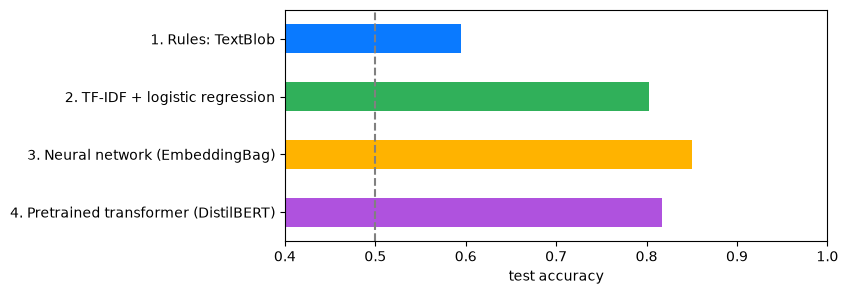

In [24]:
methods = ["TextBlob", "Log. reg.", "Neural net", "Transformer"]
scoreboard = pd.DataFrame({"test accuracy": [f"{v:.1%}" for v in results.values()],
                           "tricky sentences (of 8)": [int((tricky[m] == tricky["truth"]).sum()) for m in methods]},
                          index=list(results.keys()))
display(scoreboard)

pd.Series(results).plot.barh(color=["#0A7AFF", "#30B05A", "#FFB300", "#AF52DE"], figsize=(7, 3))
plt.axvline(0.5, color="gray", linestyle="--")
plt.xlim(0.4, 1); plt.xlabel("test accuracy"); plt.gca().invert_yaxis()
plt.show()

<span style="color:red;"><b>Question:</b> Which method would you use for a real product, for example to sort customer reviews? Think about more than accuracy.</span>

<span style="color:green;"><b>Answer:</b></span><br>
There is no single winner. It depends on what you need:

| | Accuracy | Speed | Explainable? | Needs labelled data? |
|---|---|---|---|---|
| Rules (TextBlob) | lowest | very fast | yes, every word score is visible | no |
| Logistic regression | good | very fast | yes, one weight per word | yes |
| Our neural network | good | fast | partly | yes, and more of it |
| Pretrained transformer | 81.8% (88.5% reading the end), best on the tricky sentences: 7 of 8 | slow, needs a lot of memory | hardly | no, if a fitting model exists |

- Millions of reviews a day on a small server: logistic regression may be the smart choice.
- Few labelled examples, text close to the pretraining data: the pretrained transformer.
- You must explain every decision: rules or a linear model.
- No labels at all, any topic: ask an LLM (section 14).

And always test on **your own** data: the tricky sentences showed that a good score on one test set says little about different text.

## 13. Limits: the 512-token window

DistilBERT only reads the **beginning** of a long review. Is the verdict often at the end? We let the model read the **last** 510 tokens instead of the first ones:

In [25]:
def last_part(text, n=510):
    ids = sst2_tokenizer(text, add_special_tokens=False)["input_ids"][-n:]     # the last n tokens
    return sst2_tokenizer.decode(ids)

start = time.time()
out_end = sentiment([last_part(t) for t in test_df["text"].tolist()[:N]], truncation=True, max_length=512, batch_size=8)
pred_end = np.array([1 if o["label"] == "POSITIVE" else 0 for o in out_end])
print(f"reads the beginning: {(transformer_pred == y_test[:N]).mean():.1%}")
print(f"reads the end:       {(pred_end == y_test[:N]).mean():.1%}   ({time.time() - start:.0f} s)")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (640 > 512). Running this sequence through the model will result in indexing errors


reads the beginning: 81.8%
reads the end:       88.5%   (28 s)


<span style="color:red;"><b>Question:</b> Which part of a review tells the model more: the beginning or the end? What does that say about cutting long texts?</span>

<span style="color:green;"><b>Answer:</b></span><br>
The **end**: **88.5%** instead of 81.8%, better than every other method (our network: 85.0%). In many reviews the first paragraphs retell the story, and the **verdict comes at the end** ("all in all, ...").

Cutting a text is never neutral: you decide what the model can see. Better solutions are splitting the text into parts and combining the scores, or a model with a bigger window.

## 14. Four ways to use a pretrained model, and RAG

| Way | What you give the model | Weights change? |
|---|---|---|
| **Zero-shot** | only an instruction | no |
| **Few-shot** | an instruction + a few examples in the prompt | no |
| **RAG** | an instruction + the right documents | no |
| **Fine-tuning** | thousands of labelled examples | yes |

To try zero-shot and few-shot you need a language model. *(Optional)* **LM Studio** runs a small one on your laptop, offline: install it from lmstudio.ai, download a small model (for example *Llama 3.2 1B Instruct*, about 1 GB), open the **Developer** tab and **start the server**. Then `!pip install openai` once.

In [26]:
# connection to the local LM Studio server (optional): if it is not running, the cells below say so
try:
    from openai import OpenAI
    client = OpenAI(base_url="http://localhost:1234/v1", api_key="lm-studio")   # local server, any key works
    LLM_MODEL = "llama-3.2-1b-instruct"     # use the name LM Studio shows for the model you loaded
    client.models.list()
    LLM_READY = True
except Exception as e:
    LLM_READY = False
    print("LM Studio is not running (that's fine, it is optional):", type(e).__name__)

def ask(system, user):
    if not LLM_READY:
        return "(no local model running)"
    reply = client.chat.completions.create(model=LLM_MODEL, temperature=0,
                                           messages=[{"role": "system", "content": system},
                                                     {"role": "user", "content": user}])
    return reply.choices[0].message.content.strip()

LM Studio is not running (that's fine, it is optional): APIConnectionError


**Zero-shot** and **few-shot** on our tricky sentences: the same model, only the prompt changes.

In [27]:
ZERO = "You classify movie reviews. Answer with one word: positive or negative."
FEW = ZERO + " Examples:\nGreat film! -> positive\nTotal waste of time. -> negative\nNot bad, I liked it. -> positive"

for s in tricky["sentence"][:4]:
    print(f"{s:40} zero-shot: {ask(ZERO, s):10} few-shot: {ask(FEW, s)}")

This movie was great!                    zero-shot: (no local model running) few-shot: (no local model running)
This movie was not good.                 zero-shot: (no local model running) few-shot: (no local model running)
Not bad at all, I really enjoyed it.     zero-shot: (no local model running) few-shot: (no local model running)
I didn't hate it.                        zero-shot: (no local model running) few-shot: (no local model running)


<span style="color:red;"><b>Question:</b> Why can a language model classify sentiment without any training on labelled reviews? And why can the answers change when we only change the prompt?</span>

<span style="color:green;"><b>Answer:</b></span><br>
The model was pretrained on so much text that it has seen people talk about positive and negative reviews countless times: the task is described in plain English, and it already knows the words. That is **zero-shot**.

The prompt is all the model gets, so a different wording or a few examples (**few-shot**) change what it predicts as the next token. Small local models are especially sensitive to this.

### A mini RAG on our reviews

**RAG** = look up the right documents first, then let the language model answer from them. Steps 1 to 4 run offline; for the search we use TF-IDF and cosine similarity from lesson 1 (real systems use embeddings: same idea, vectors and cosine).

In [28]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# 1. Split: every review into chunks of 3 sentences
chunks = []
for fileid, text in zip(df["fileid"], df["text"]):
    sentences = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if len(s.split()) > 3]
    for i in range(0, len(sentences), 3):
        chunk = " ".join(sentences[i:i + 3])
        if len(chunk.split()) >= 25:
            chunks.append({"fileid": fileid, "text": chunk})
chunks = pd.DataFrame(chunks)

# 2. Embed + 3. Store: one TF-IDF vector per chunk
rag_vec = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | {"reviewers", "say", "film", "movie"}), sublinear_tf=True)
chunk_vectors = rag_vec.fit_transform(chunks["text"])
print("chunks:", len(chunks))

# 4. Retrieve: the chunks closest to the question (cosine similarity)
def retrieve(question, k=3, only=None):
    sims = (chunk_vectors @ rag_vec.transform([question]).T).toarray().ravel()
    if only is not None:
        sims = np.where(chunks["fileid"].isin(only), sims, -1)      # search only in these documents
    top = np.argsort(-sims)[:k]
    return chunks.iloc[top].assign(similarity=sims[top].round(3))

question = "What do reviewers say about the special effects in Titanic?"
retrieve(question)

chunks: 21574


,fileid,text,similarity
13759,pos/cv315_11629.txt,"he succeeds masterfully . cameron does two things that work incredibly well . first , he shows us modern-day salvage...",0.354
9778,neg/cv937_9816.txt,"and he must of been on some drug when he wrote the final ten minutes , which are awful . the special effects look ni...",0.353
1401,neg/cv135_12506.txt,"well , yes and no . although the special effects should be impressive , with a massive tidal wave destroying new yor...",0.348


<span style="color:red;"><b>Question:</b> Read the three chunks. Are they all about <i>Titanic</i>? What went wrong?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Not all of them: the search finds chunks about **special effects in other films**. TF-IDF matches words, and many reviews compare other films with *Titanic* or talk about effects. This is the most common RAG problem: **wrong chunks in, wrong answer out**.

A common fix is to **filter first**: only search in documents that are really about the topic. Here: the reviews that mention *titanic* at least 5 times.

In [29]:
titanic_reviews = df.loc[df["text"].str.count("titanic") >= 5, "fileid"]
found = retrieve(question, only=titanic_reviews)
display(found)

# 5. Augment: put the chunks into the prompt
context = "\n\n".join(f"[{r.fileid}] {r.text}" for r in found.itertuples())
prompt = f"Answer the question using only these review excerpts. Name the review files you used.\n\n{context}\n\nQuestion: {question}"

# 6. Generate (optional, needs LM Studio)
print(ask("You answer questions about movie reviews.", prompt))

,fileid,text,similarity
13759,pos/cv315_11629.txt,"he succeeds masterfully . cameron does two things that work incredibly well . first , he shows us modern-day salvage...",0.354
15308,pos/cv453_10379.txt,"in this way , titanic possesses a depth not usually found in action pictures . you don't just get a love story with ...",0.309
13176,pos/cv261_10954.txt,"firstly , there's cameron's direction . there are some great sweeping shots of the titanic , and some clever fades b...",0.308


(no local model running)


<span style="color:red;"><b>Question:</b> Why does the prompt say <i>"using only these review excerpts"</i> and <i>"name the review files"</i>?</span>

<span style="color:green;"><b>Answer:</b></span><br>
**Grounding**: the model should answer from **our documents**, not from what it remembers, because memory can be wrong or invented (hallucinations). Asking for the **sources** lets a person check the answer.

RAG gives the model **knowledge** (here: what our reviewers wrote). Fine-tuning would change its **behaviour**. And just like our sentiment models, a RAG system needs a fair test: a fixed set of questions with known answers.

## 15. Recap of part 1

| Section | What we learned |
|---|---|
| 1–2 | All three earlier methods are bags of words: *"not good"* and *"good not"* get the same score. |
| 3 | A transformer: embeddings + positions + 6 blocks of attention and feed-forward, 67 million weights. |
| 4 | Query, key, value: *hate* looks 65% at *didn't* and becomes *"not hate"*. |
| 5 | Attention alone ignores order; position vectors fix that (512 learned positions). |
| 6 | Masked self-attention only looks back; the window limits how far attention can look. |
| 7–8 | Same size in and out of every block; subword tokens, no unknown words. |
| 9 | One sentence: tokens → vectors → 6 blocks → `[CLS]` → classifier → softmax. |
| 10–11 | Pretraining by guessing hidden words, fine-tuning on SST-2: transfer learning. |
| 12–13 | The showdown, and what the 512-token cut costs. |
| 14 | Zero-shot, few-shot, RAG, fine-tuning; RAG = search + an LLM. |

**Key takeaways:**
- **Attention** lets every word look at the others: the same word gets a different vector in a different sentence.
- **Pretraining + fine-tuning = transfer learning**: knowledge from huge text, reused for our task.
- **The best model depends on the job**, not only on the accuracy.

# Part 2: the whole project in one cell

Everything from lessons 1, 2 and 3 in **one cell**, with only the major steps commented. This is the complete workflow of a text-classification project, from the raw data to the scoreboard. It runs on its own: you can restart the notebook and run only this cell (🤗 it needs the DistilBERT model, from the `models` folder or downloaded).

| Step | What happens |
|---|---|
| 1. Data | load the reviews, labels as 0 / 1 |
| 2. Split | training / validation / test, test used once |
| 3–6. Models | rules, TF-IDF + logistic regression, our neural network, the pretrained transformer (reading the beginning and the end) |
| 7. Evaluate | test accuracy and the tricky sentences, side by side |

In [ ]:
import os, re, time
from collections import Counter
import numpy as np, pandas as pd, torch, torch.nn as nn
from textblob import TextBlob
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from transformers import pipeline

def natural_language_processing():          # a function, so the variables of part 1 stay untouched
    # 1. Data: 2,000 movie reviews, label 1 = positive, 0 = negative; 8 tricky sentences
    df = pd.read_csv("movie_reviews.csv")
    df["y"] = (df["label"] == "pos").astype(int)
    tricky = pd.DataFrame({"sentence": ["This movie was great!", "This movie was not good.", "Not bad at all, I really enjoyed it.",
                                        "I didn't hate it.", "I loved the trailer, but the film was a disaster.",
                                        "Oh great, another two hours of my life I will never get back.",
                                        "The acting was terrible but the story was wonderful.", "Absolutely brilliant, a must-see!"],
                           "truth": [1, 0, 1, 1, 0, 0, 1, 1]})

    # 2. Split: 1,280 training, 320 validation (to choose), 400 test (to measure once)
    train, test = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)
    train, val = train_test_split(train, test_size=0.2, stratify=train["y"], random_state=42)
    scores = {}                                   # method -> (test accuracy, predictions for the tricky sentences)

    # 3. Rules: TextBlob polarity > 0 means positive (no training)
    rules = lambda texts: np.array([int(TextBlob(t).sentiment.polarity > 0) for t in texts])
    scores["Rules: TextBlob"] = ((rules(test["text"]) == test["y"]).mean(), rules(tricky["sentence"]))

    # 4. Bag of words: TF-IDF + logistic regression, trained on training + validation
    train_full = pd.concat([train, val])
    vec = TfidfVectorizer()
    logreg = LogisticRegression(max_iter=1000).fit(vec.fit_transform(train_full["text"]), train_full["y"])
    scores["TF-IDF + logistic regression"] = (logreg.score(vec.transform(test["text"]), test["y"]),
                                              logreg.predict(vec.transform(tricky["sentence"])))

    # 5. Neural network: learned embeddings (64 per word), averaged, one neuron; best epoch chosen on validation
    tok = lambda t: re.findall(r"[a-z]+(?:'[a-z]+)?", t.lower())
    counts = Counter(w for t in train["text"] for w in tok(t))
    vocab = {w: i + 1 for i, w in enumerate(w for w, c in counts.items() if c >= 2)}     # 0 = unknown word
    def batch(texts):
        ids = [torch.tensor([vocab.get(w, 0) for w in tok(t)]) for t in texts]
        return torch.cat(ids), torch.tensor([0] + [len(x) for x in ids[:-1]]).cumsum(0)
    torch.manual_seed(0); rng = np.random.default_rng(0)
    net = nn.Sequential()                                     # a container for the three layers
    net.emb, net.drop, net.out = nn.EmbeddingBag(len(vocab) + 1, 64, mode="mean"), nn.Dropout(0.3), nn.Linear(64, 1)
    score = lambda texts: net.out(net.drop(net.emb(*batch(texts)))).squeeze(1)
    opt, loss_fn, best = torch.optim.Adam(net.parameters(), lr=0.005), nn.BCEWithLogitsLoss(), (0, None)
    for epoch in range(20):
        net.train()
        order = rng.permutation(len(train))
        for s in range(0, len(train), 32):
            part = train.iloc[order[s:s + 32]]
            loss = loss_fn(score(part["text"].tolist()), torch.tensor(part["y"].values, dtype=torch.float32))
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            val_acc = ((score(val["text"].tolist()) > 0).numpy() == val["y"].values).mean()
        if val_acc > best[0]:
            best = (val_acc, {k: v.clone() for k, v in net.state_dict().items()})
    net.load_state_dict(best[1]); net.eval()
    with torch.no_grad():
        scores["Neural network (EmbeddingBag)"] = (((score(test["text"].tolist()) > 0).numpy() == test["y"].values).mean(),
                                                   (score(tricky["sentence"].tolist()) > 0).numpy().astype(int))

        # 6. Transformer: DistilBERT, pretrained + fine-tuned on SST-2, no training on our data (reads the first or the last 512 tokens)
    name = "distilbert-base-uncased-finetuned-sst-2-english"
    model = os.path.join("models", name) if os.path.isdir(os.path.join("models", name)) else "distilbert/" + name   # local folder first
    sentiment = pipeline("sentiment-analysis", model=model)
    transformer = lambda texts: np.array([int(o["label"] == "POSITIVE")
                                          for o in sentiment(list(texts), truncation=True, max_length=512, batch_size=8)])
    scores["Pretrained transformer (DistilBERT)"] = ((transformer(test["text"]) == test["y"]).mean(), transformer(tricky["sentence"]))
    end = lambda t: sentiment.tokenizer.decode(sentiment.tokenizer(t, add_special_tokens=False)["input_ids"][-510:])   # the last 510 tokens
    scores["Pretrained transformer, reading the end"] = ((transformer(test["text"].map(end)) == test["y"]).mean(), transformer(tricky["sentence"].map(end)))

    # 7. Evaluate: all methods on the same 400 test reviews and the same 8 tricky sentences
    return pd.DataFrame({"test accuracy": {m: f"{a:.1%}" for m, (a, _) in scores.items()},
                         "tricky (of 8)": {m: int((p == tricky["truth"]).sum()) for m, (_, p) in scores.items()}})

natural_language_processing()

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (640 > 512). Running this sequence through the model will result in indexing errors


,test accuracy,tricky (of 8)
Rules: TextBlob,59.5%,4
TF-IDF + logistic regression,80.2%,2
Neural network (EmbeddingBag),85.0%,3
Pretrained transformer (DistilBERT),81.8%,7
"Pretrained transformer, reading the end",88.5%,7


## (Optional) Marvin, the friendly chatbot, now with a transformer

Marvin from lesson 2 had three parts. We swap the **mood** part for the transformer:

| Part | Lesson 2 | Now |
|---|---|---|
| 1. Mood | our averaged-embeddings network | **DistilBERT** (section 9): reads *didn't* together with *hate* |
| 2. Topic | GloVe cosine | GloVe cosine (embeddings) |
| 3. Follow-up | GloVe cosine | GloVe cosine (embeddings) |

**For your project:** change the `TOPICS` list, the replies or the thresholds.

In [31]:
# GloVe (lesson 2): the packed .gz or an unpacked file in the notebook's folder
candidates = ["glove-wiki-gigaword-50.gz", "glove-wiki-gigaword-50", "glove-wiki-gigaword-50.txt"]
found = [f for f in candidates if os.path.exists(os.path.join(DATA_DIR, f))]
if not found:
    raise FileNotFoundError("GloVe file not found: put glove-wiki-gigaword-50.gz in the same folder as this notebook.")
GLOVE_FILE = os.path.join(DATA_DIR, found[0])
open_file = gzip.open if GLOVE_FILE.endswith(".gz") else open
glove = {}
with open_file(GLOVE_FILE, "rt", encoding="utf8") as f:
    next(f)                                   
    for i, line in enumerate(f):
        if i == 100_000:
            break
        parts = line.rstrip().split(" ")
        glove[parts[0]] = np.array(parts[1:], dtype=np.float32)
print("GloVe words loaded:", len(glove))

def cosine(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

GloVe words loaded: 100000


In [32]:
TOPICS = ["comedy", "horror", "thriller", "romance", "western", "animation", "documentary", "musical", "war", "fantasy",
          "actor", "actress", "director", "plot", "ending", "dialogue", "soundtrack", "effects", "costumes", "cinema"]
IGNORE = {"film", "films", "movie", "movies", "love", "like", "really", "today", "yesterday"}   # too general to be a topic

def find_mood(message):
    """Part 1: probability that the message is positive, from the transformer."""
    o = sentiment(message)[0]
    return o["score"] if o["label"] == "POSITIVE" else 1 - o["score"]

def find_topic(message, min_similarity=0.65):
    """Part 2: the topic closest to any word of the message (GloVe cosine)."""
    best_topic, best_word, best_sim = None, None, min_similarity
    for w in tokenize(message):
        if w in ENGLISH_STOP_WORDS or w in IGNORE or w not in glove:
            continue
        for t in TOPICS:
            sim = cosine(glove[w], glove[t])
            if sim > best_sim:
                best_topic, best_word, best_sim = t, w, sim
    return best_topic, best_word

def next_topic(topic):
    """Part 3: the topic closest to this one, for a follow-up question."""
    return max((t for t in TOPICS if t != topic), key=lambda t: cosine(glove[topic], glove[t]))

def marvin(message):
    p_pos = find_mood(message)
    if p_pos > 0.7:
        reply = random.choice(["That sounds great!", "Wonderful, I'm happy for you!"])
    elif p_pos < 0.3:
        reply = random.choice(["Oh no, that sounds disappointing.", "I'm sorry to hear that."])
    else:
        reply = random.choice(["I see.", "Hmm, tell me more."])
    reply += f" (I'm {p_pos:.0%} sure you liked it.)"
    topic, word = find_topic(message)
    if topic is None:
        return reply + " What kind of films do you like?"
    if word != topic:
        reply += f" '{word}' sounds like {topic} to me."
    return reply + f" And what do you think about {next_topic(topic)}?"

random.seed(1)
for message in ["I watched an amazing science fiction film yesterday",
                "The plot was boring and the acting was terrible",
                "I didn't hate the new comedy",
                "I fell asleep during the scary movie"]:
    print("You:   ", message)
    print("Marvin:", marvin(message))
    print(f"        (lesson-2 network: {predict_net([message])[0]:.0%} positive)")
    print()

You:    I watched an amazing science fiction film yesterday
Marvin: That sounds great! (I'm 100% sure you liked it.) 'fiction' sounds like fantasy to me. And what do you think about horror?
        (lesson-2 network: 100% positive)

You:    The plot was boring and the acting was terrible
Marvin: Oh no, that sounds disappointing. (I'm 0% sure you liked it.) And what do you think about thriller?
        (lesson-2 network: 0% positive)

You:    I didn't hate the new comedy
Marvin: Wonderful, I'm happy for you! (I'm 100% sure you liked it.) And what do you think about musical?
        (lesson-2 network: 0% positive)

You:    I fell asleep during the scary movie
Marvin: Oh no, that sounds disappointing. (I'm 0% sure you liked it.) 'scary' sounds like horror to me. And what do you think about thriller?
        (lesson-2 network: 0% positive)



To chat with Marvin yourself, remove the `#` in front of the lines below and run the cell. Type **bye** to stop.

In [33]:
# print("Hello, I am Marvin, I love talking about films. Type 'bye' to stop.")
# while True:
#     user_input = input("> ")
#     if user_input.lower() == "bye":
#         print("It was nice talking to you, goodbye!")
#         break
#     print(marvin(user_input))

## (Optional) A text generator with a transformer

In lesson 2 our generator read the last 3 words through a hidden layer. Now we build a **tiny GPT**: embeddings + positions + **masked self-attention** blocks (sections 5–7), trained to predict the **next token** on our training reviews.

| Part | Lesson 2 generator | Tiny GPT |
|---|---|---|
| Input | the last 3 words | the last 32 tokens |
| Inside | embedding → 128 ReLU neurons | embedding + positions → 2 blocks of masked self-attention + feed-forward |
| Output | softmax over 5,000 words | softmax over 5,000 words |

Training takes a few minutes on a laptop. **For your project:** change `CONTEXT`, `D_MODEL`, `N_LAYERS` or the number of steps.

In [34]:
def tokens_with_punct(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|[.!?,]", text.lower())    

all_tokens = [w for t in train_df["text"] for w in tokens_with_punct(t)]
gen_vocab = ["<unk>"] + [w for w, _ in Counter(all_tokens).most_common(4999)]   
gen_idx = {w: i for i, w in enumerate(gen_vocab)}
ids_all = torch.tensor([gen_idx.get(w, 0) for w in all_tokens])
print("tokens in the training reviews:", f"{len(ids_all):,}")

CONTEXT, D_MODEL, N_HEADS, N_LAYERS = 32, 128, 4, 2

class TinyGPT(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, D_MODEL)          
        self.pos_emb = nn.Embedding(CONTEXT, D_MODEL)             
        block = nn.TransformerEncoderLayer(D_MODEL, N_HEADS, dim_feedforward=4 * D_MODEL,
                                           dropout=0.1, batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(block, N_LAYERS)       
        self.out = nn.Linear(D_MODEL, vocab_size)                 
        self.register_buffer("mask", nn.Transformer.generate_square_subsequent_mask(CONTEXT))  

    def forward(self, x):
        n = x.shape[1]
        h = self.tok_emb(x) + self.pos_emb(torch.arange(n))       
        h = self.blocks(h, mask=self.mask[:n, :n], is_causal=True)   
        return self.out(h)

torch.manual_seed(0)
gpt = TinyGPT(len(gen_vocab))
print(f"weights: {sum(p.numel() for p in gpt.parameters()):,}")

tokens in the training reviews: 929,006
weights: 1,685,640


/var/folders/b4/wg2kcb250nngc99tvt4v17nw0000gn/T/ipykernel_95366/1188702446.py:19: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.blocks = nn.TransformerEncoder(block, N_LAYERS)


In [35]:
optimizer = torch.optim.Adam(gpt.parameters(), lr=0.002)
loss_fn = nn.CrossEntropyLoss()
g = torch.Generator().manual_seed(0)
STEPS, BATCH = 1500, 64
start = time.time()
gpt.train()
for step in range(1, STEPS + 1):
    starts = torch.randint(0, len(ids_all) - CONTEXT - 1, (BATCH,), generator=g)
    x = torch.stack([ids_all[s:s + CONTEXT] for s in starts])           
    y = torch.stack([ids_all[s + 1:s + CONTEXT + 1] for s in starts])    
    loss = loss_fn(gpt(x).reshape(-1, len(gen_vocab)), y.reshape(-1))
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    if step % 300 == 0:
        print(f"step {step} | loss {loss.item():.2f} | {time.time() - start:.0f} s")

step 300 | loss 5.09 | 23 s
step 600 | loss 4.84 | 49 s
step 900 | loss 4.68 | 77 s
step 1200 | loss 4.62 | 101 s
step 1500 | loss 4.55 | 123 s


In [37]:
def generate(seed, length=25, temperature=0.8):
    gpt.eval()
    words = tokens_with_punct(seed)
    for _ in range(length):
        x = torch.tensor([[gen_idx.get(w, 0) for w in words[-CONTEXT:]]])
        with torch.no_grad():
            scores = gpt(x)[0, -1]                                      
        scores[0] = -1e9                                               
        if temperature == 0:
            nxt = int(scores.argmax())                                  
        else:
            p = torch.softmax(scores / temperature, dim=0)              
            nxt = int(torch.multinomial(p, 1, generator=g))
        words.append(gen_vocab[nxt])
    return " ".join(words)

g.manual_seed(1)
print("temperature 0:  ", generate("the acting is", temperature=0))
for t in [0.5, 0.8, 1.2]:
    print(f"temperature {t}:", generate("the acting is", temperature=t))

temperature 0:   the acting is a good film that is a shame that is a good idea that he is a good idea of the film . the film is
temperature 0.5: the acting is a good film . if you don't know how to do you see it really get a good movie . the only problem is a
temperature 0.8: the acting is set out to control , and yet to become evident in that they do something else . the big screen , unfortunately that american pie
temperature 1.2: the acting is john carpenter's chan game lou dialogue ? i keep your much is , the dvd sort . shock wouldn't be more money at warner standard


### *(Optional)* A pretrained GPT: DistilGPT-2

Our tiny GPT read 900,000 tokens for a few minutes. **DistilGPT-2** has the same building blocks, but 82 million weights, pretrained on millions of web pages. 🤗 *Downloads about 350 MB.*

In [38]:
writer = pipeline("text-generation", model=local_or_hub("distilbert/distilgpt2"))
for out in writer("The acting in this movie is", max_new_tokens=30, do_sample=True, temperature=0.8,
                  num_return_sequences=2, pad_token_id=50256):
    print("-", out["generated_text"])

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

- The acting in this movie is to be directed by Daniel Cipes and directed by Michael Reuven. This is the first film in the series. This is the first film in
- The acting in this movie is as an action/action movie as it is a romantic comedy. It's an action movie and that's what it is. I hope the action film


## Recap

| Section | What we learned |
|---|---|
| 1. Three methods | Rules 59.5%, TF-IDF + logistic regression 80.2%, our network 85.0%, but at most 4 of 8 tricky sentences: all three treat each word **on its own**. |
| 2. Context | Averaging ignores order: *"This movie was not good."* and *"This movie was good not."* both get 0.457. *plot* has **one** vector in every sentence. |
| 3. Transformer | Embeddings + positions + 6 blocks of attention and feed-forward: 67 million weights, 768 numbers per token. |
| 4. Attention | Query, key, value: score, softmax, mix. *hate* looks 65% at *didn't*: (0, 1, 0) becomes (0.65, 0.12, 0.23), *"not hate"*. |
| 5. Positions | Attention alone ignores order: *boy* gets the same vector in *"boy likes girl"* and *"girl likes boy"*. A learned **position vector** is added to each word: 512 positions, so at most 512 tokens. |
| 6. How far attention looks | Masked self-attention only looks **back** (GPT, writing). The window limits attention: 84% of our reviews are longer than 512 tokens. |
| 7. Blocks | Same size in and out of every block. The word table is the biggest single table (23.4 million weights); the classifier on top is tiny. |
| 8. Subword tokens | WordPiece, 30,522 tokens: *Filmkritik* → `film ##kr ##iti ##k`, no unknown words. `[CLS]` stands for the whole text. |
| 9. One sentence | Tokens → vectors → 6 blocks → `[CLS]` → classifier (768 → 768 → 2) → softmax: *"I didn't hate it."* is 0.992 positive. |
| 10. Pretraining | Guess the hidden word, no labels needed. After *but*, it guesses *disaster, disappointment, flop*: it learned opinions from guessing words. |
| 11. Fine-tuning | Pretrained blocks + a new classifier, fine-tuned on SST-2: **transfer learning**. 7 of 8 tricky sentences without seeing our reviews; only sarcasm fails. |
| 12. Showdown | 81.8% on our reviews: below our network (85.0%), but best on the tricky sentences. The best method depends on the job. |
| 13. Limits | Reading the **end** instead of the beginning: 88.5%, the best of all. Cutting a text decides what the model can see. |
| 14. Using a pretrained model | Zero-shot, few-shot, RAG, fine-tuning: start with the cheapest. RAG = search + an LLM; wrong chunks in, wrong answer out. |
| Part 2 | The whole project in one cell: data → split → four models (the transformer twice: beginning and end) → scoreboard.
| Part 3 | Marvin with DistilBERT for the mood. A tiny GPT: embeddings + positions + masked self-attention, trained to guess the next token; temperature controls how random it writes. |

**Key takeaways:**

- **Attention** lets every word look at the others: the same word gets a different vector in a different sentence.
- **Positions** give the order back: attention alone sees a bag of words.
- **Pretraining + fine-tuning = transfer learning**: knowledge from huge amounts of text, reused for our task in one line of code.
- **The best model depends on the job**: accuracy, speed, explainability, labelled data. And always test on **your own** data.
- **Using LLMs**: zero-shot → few-shot → RAG → fine-tuning. RAG gives the model knowledge, fine-tuning changes its behaviour.

**End of the NLP series.** From rules and tf-idf logistic regression (lesson 1) to embeddings (lesson 2) to transformers (lesson 3): each step needed fewer hand-written rules and more data or pretraining. *Optional:* fine-tune a transformer on our reviews (needs a GPU).